# 1 · What does “trapped and more jiggly” mean?

This is a **synthetic methods experiment**, not a conclusion about real killer cells.
We ask whether inference can recover known target-associated changes and avoid
attributing spontaneous movement changes or mechanical trapping to those effects.

The supplied `mantishrimp` ABM is retained, with optional proximity-response fields
whose zero defaults preserve its original behavior. The reduced model keeps OU motility,
periodic geometry, and optional target movement, repulsion, and stochastic adhesion.
Cytotoxicity, exhaustion, per-step event tables, and within-type cell forces are omitted.
Consequently its timing against the full ABM is **not** an equivalent-model speedup.
The NumPy-reference versus Numba timing below does compare the same reduced model.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from io import BytesIO
import json
import os
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'pyproject.toml').is_file()
             and (p / 'src' / 'motility_inference').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Launch this notebook from the project or its notebooks directory.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
RESULTS = ROOT / 'results' / 'synthetic_v1'
RUN_TRAINING = False  # Large simulation banks and MCMC are never launched by default.
(ROOT / '.cache').mkdir(exist_ok=True)
os.environ.setdefault('XDG_CACHE_HOME', str(ROOT / '.cache'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache' / 'matplotlib'))

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
from motility_inference.simulator import SimConfig, simulate, load_dataset, proximity
from motility_inference.priors import PARAMETER_NAMES, PRIOR_LOW, PRIOR_HIGH, scenario_theta

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})

def show(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format='png', dpi=130, bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

def read_json(name):
    path = RESULTS / name
    if not path.is_file():
        return None
    try:
        return json.loads(path.read_text())
    except json.JSONDecodeError:
        print(f'{name} is being updated; rerun this cell after the benchmark finishes.')
        return None

print('Project:', ROOT)
print('Cached results:', RESULTS)

Project: /Users/marsian/PhD_LifeSciRes/cell_motility
Cached results: /Users/marsian/PhD_LifeSciRes/cell_motility/results/synthetic_v1


For nearest-target surface gap $d_i(t)$, define
$$
g_i(t)=\exp[-\max(d_i(t),0)/\ell].
$$
The three effects enter log parameters: $\log s_i=\log s_0+u_i+\delta_sg_i$,
$\log\tau_i=\log\tau_0+\delta_\tau g_i$, and
$\log j_i=\log j_0+\delta_jg_i$, with $u_i\sim N(0,\sigma_u^2)$.
The gate is one at contact and tends to zero far away; $\exp(\delta)$ is a contact/far ratio.

- **Active amplitude $s$:** stationary SD of each OU velocity coordinate, not mean observed speed.
- **Persistence time $\tau$:** time scale of active-velocity memory.
- **Jitter $j$:** translational Brownian amplitude, with units length / square-root time.

Reduced amplitude, shorter persistence, and increased jitter can yield slower net
progress with more local fluctuations. They are separate mechanisms, not synonyms.
Localization noise also produces apparent jiggling and is modeled separately.

In [2]:
config = SimConfig()
experiments = {name: simulate(scenario_theta(name), config, seed=103)
               for name in ('null', 'combined')}
table = []
for name, data in experiments.items():
    gate, gap, _, _ = proximity(data['positions'], data['targets'],
        config.box_size, config.contact_distance, config.interaction_length)
    table.append({'scenario': name, 'near_fraction_gate_above_half': (gate > .5).mean(),
                  'far_fraction_gate_below_point2': (gate < .2).mean(),
                  'amplitude_contact_ratio': np.exp(data['theta'][3]),
                  'persistence_contact_ratio': np.exp(data['theta'][4]),
                  'jitter_contact_ratio': np.exp(data['theta'][5])})
display(pd.DataFrame(table).set_index('scenario'))
display(pd.Series(asdict(config), name='simulation design'))

,near_fraction_gate_above_half,far_fraction_gate_below_point2,amplitude_contact_ratio,persistence_contact_ratio,jitter_contact_ratio
scenario,,,,,
null,0.232587,0.497098,1.000000,1.000000,1.000000
combined,0.287313,0.487562,0.449329,0.449329,2.225541


n_killers                 12.00
n_targets                  9.00
n_frames                 201.00
frame_dt                   0.25
substeps                   1.00
box_size                 180.00
contact_distance          12.00
interaction_length        10.00
localization_sd            0.15
heterogeneity_sd           0.25
target_speed               0.00
target_tau                 2.00
repulsion                  0.00
binding_rate               0.00
unbinding_rate             0.50
adhesion                   0.00
capture_radius_factor      1.50
spontaneous_sd             0.00
spontaneous_tau            5.00
Name: simulation design, dtype: float64

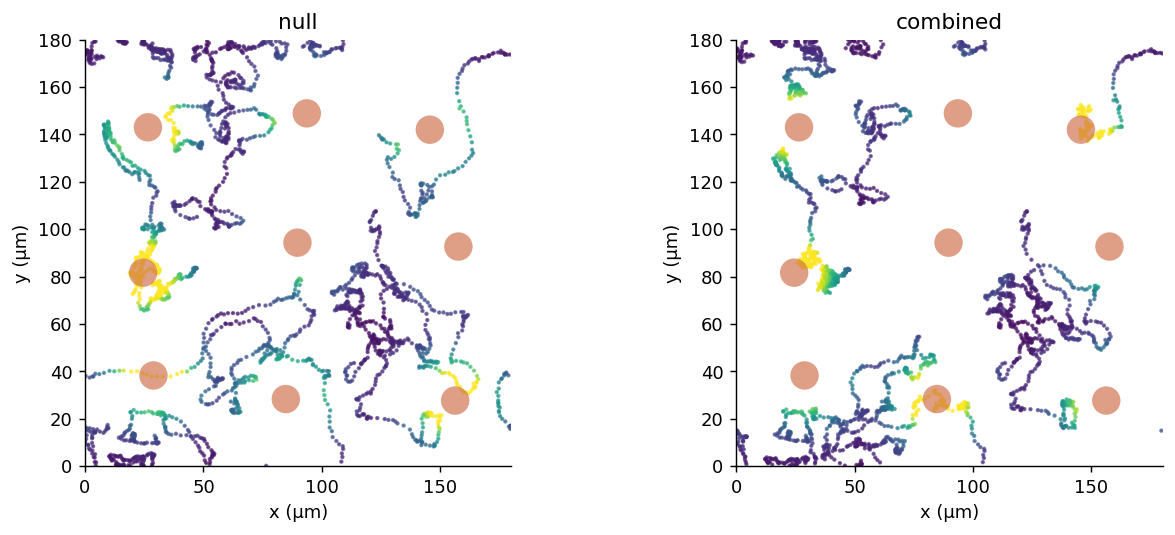

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, (name, data) in zip(axes, experiments.items()):
    gate, _, _, _ = proximity(data['positions'], data['targets'],
        config.box_size, config.contact_distance, config.interaction_length)
    # Points avoid drawing artificial connecting lines across periodic seams.
    points = data['positions'] % config.box_size
    ax.scatter(points[..., 0].ravel(), points[..., 1].ravel(),
               c=gate.ravel(), cmap='viridis', s=2, vmin=0, vmax=1, alpha=.65)
    for target in data['targets'][:, 0]:
        ax.add_patch(plt.Circle(target, config.contact_distance / 2,
                               facecolor='#ce6c47', alpha=.65))
    ax.set(xlim=(0, config.box_size), ylim=(0, config.box_size),
           xlabel='x (µm)', ylabel='y (µm)', title=name)
    ax.set_aspect('equal')
show(fig)

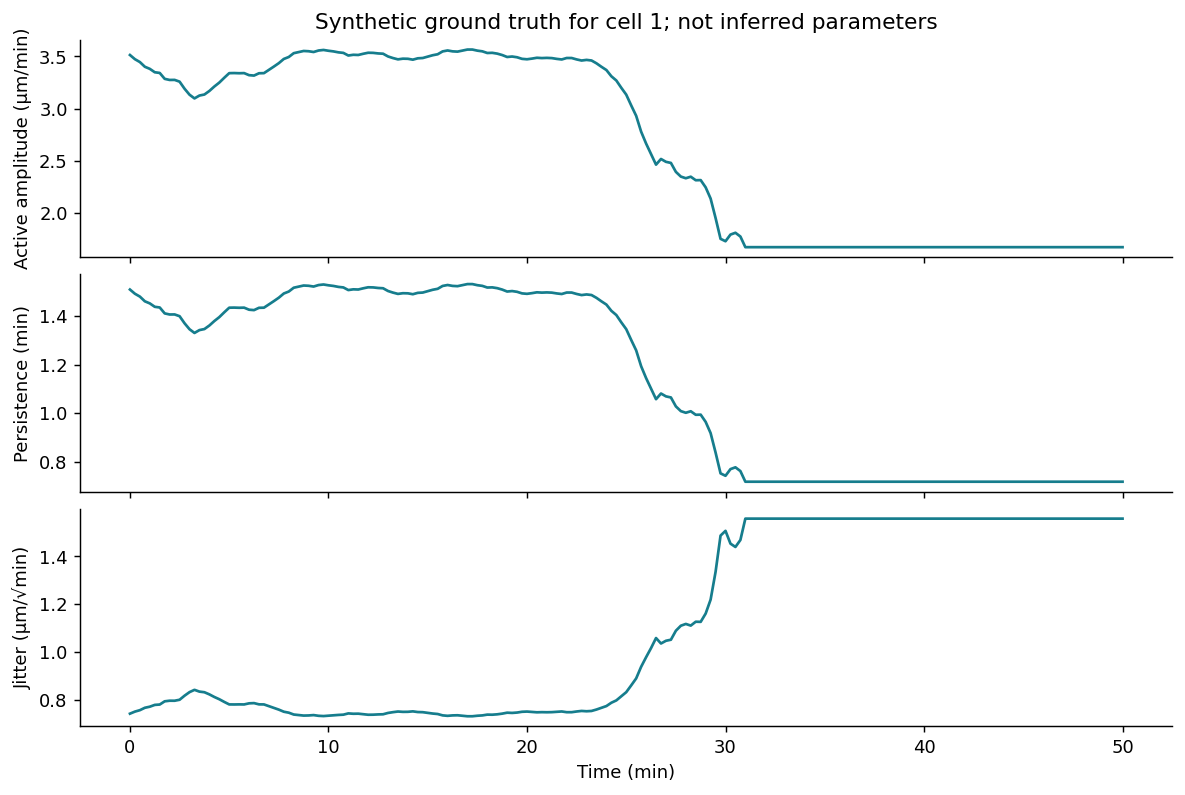

In [4]:
data = experiments['combined']
gate, gap, _, _ = proximity(data['positions'], data['targets'],
    config.box_size, config.contact_distance, config.interaction_length)
# Choose a track with exposure variation for illustration, not performance evaluation.
cell = int(np.argmax(np.std(gate, axis=1)))
truth_gate = data['true_gate'][cell]
fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True, constrained_layout=True)
for ax, label, b, e in zip(axes, ('Active amplitude (µm/min)', 'Persistence (min)',
                                 'Jitter (µm/√min)'), (0, 1, 2), (3, 4, 5)):
    offset = data['cell_offsets'][cell] if b == 0 else 0
    values = np.exp(data['theta'][b] + offset + data['theta'][e] * truth_gate)
    ax.plot(data['times'], values, color='#167d8d')
    ax.set_ylabel(label)
axes[-1].set_xlabel('Time (min)')
axes[0].set_title(f'Synthetic ground truth for cell {cell}; not inferred parameters')
show(fig)

The joint OU velocity/displacement transition is exact for coefficients frozen within
one integration step. Spatially changing coefficients and mechanical forces still
require a substep-convergence check. Observation cadence and integration step are
different settings. Target-independent spontaneous amplitude changes and
adhesion are retained as stress tests.

In [5]:
speed = read_json('speed.json')
if speed is None:
    print('No cached timing study. Run: python scripts/run_synthetic_benchmark.py --stage speed')
else:
    display(pd.Series({
        'same reduced-model speedup': speed['same_model_speedup'],
        'paired engine maximum error': speed['paired_engine_max_absolute_difference'],
        'Numba median seconds': speed['timings']['numba']['median_seconds'],
        'NumPy reference median seconds': speed['timings']['numpy']['median_seconds'],
    }))
    print(speed['supplied_abm_comparison_note'])

same reduced-model speedup        189.183765
paired engine maximum error         0.000000
Numba median seconds                0.000327
NumPy reference median seconds      0.061843
dtype: float64

Similar free-motion design, but different initialization/integrator/output; not a numerical-equivalence speedup.


The source ABM now also exposes `killer_delta_speed`, `killer_delta_tau`, and
`killer_delta_jitter`, with `target_interaction_length` setting the response scale.
Its explicit polarity/Euler update and initialization remain distinct from the
reduced integrated-velocity simulator. Independent source-ABM validation below is
therefore a transfer test, not another draw from the training generator.

In [6]:
from mantishrimp.config import MotilityConfig
source_defaults = MotilityConfig()
display(pd.Series({name: getattr(source_defaults, name) for name in
    ('target_interaction_length', 'killer_delta_speed', 'killer_delta_tau', 'killer_delta_jitter')},
    name='optional source-ABM response defaults'))
reference = read_json('reference_validation.json')
if reference:
    rows = []
    for case, result in reference.items():
        for method, aggregate in result['aggregate'].items():
            rows.append({'source_ABM_case': case, 'method': method, 'datasets': aggregate['n'],
                         'any_direction_detected': aggregate['any_detection_rate']})
    display(pd.DataFrame(rows))
    print('These raw transfer-test decisions are exploratory. The guarded API identifies the known generator mismatch and abstains.')
else:
    print('Independent source-ABM validation is not available yet; no transfer claim is made.')

target_interaction_length    10.0
killer_delta_speed            0.0
killer_delta_tau              0.0
killer_delta_jitter           0.0
Name: optional source-ABM response defaults, dtype: float64

,source_ABM_case,method,datasets,any_direction_detected
0,reference_null,neural,16,0.0000
1,reference_null,abc,16,0.0000
2,reference_combined,neural,16,1.0000
3,reference_combined,abc,16,0.1250
4,reference_mechanics,neural,16,0.0625
5,reference_mechanics,abc,16,0.0000


These raw transfer-test decisions are exploratory. The guarded API identifies the known generator mismatch and abstains.


Continue to notebook 2 for likelihood-based inference and notebook 3 for
likelihood-free inference. Their performance is assessed on independent whole
simulated movies in notebook 4. Frames within a movie are not independent replicates.